# Q4-Q6: controlled Intel Arc XPU experiments
Review revision: local skip path in every model; graph models add a separate graph term. FP32; hidden dimension 16; node embeddings 10 with standard-normal initialization; Adam 0.002 (weight decay 0.0001 on forecasting weights, zero on embeddings); batch 64; maximum 40 epochs; patience 5; seed 25280025. Per-sensor training-only scaling; masked original-unit MAE loss divided by one common training scale. Every epoch uses all training windows. Full validation MAE selects checkpoints; final test evaluation follows selection.

In [1]:
from pathlib import Path
import sys, subprocess, json
from IPython.display import display, Image
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
assert (ROOT/'src').is_dir()
def run(script,*args):
    command=[sys.executable,str(ROOT/'src'/script),*args]
    log=ROOT/'results'/(script.replace('.py','')+('_'+args[-1] if args else '')+'.log')
    with log.open('w',encoding='utf-8') as f:
        result=subprocess.run(command,cwd=ROOT,stdout=f,stderr=subprocess.STDOUT)
    print(log.read_text(encoding='utf-8')[-16000:])
    result.check_returncode()
def show(name):
    display(Image(filename=str(ROOT/'figures'/name)))

In [2]:
import torch
print(torch.__version__,torch.xpu.is_available(),torch.xpu.get_device_name())
assert torch.xpu.is_available()

2.14.1+xpu True Intel(R) Arc(TM) 140T GPU (23GB)


## Model implementation
All models retain each sensor's local representation through a shared local projection. The graph models add a separate projection of adjacency-mixed features before ReLU. The temporal baseline omits that graph term. Fixed adjacency clears the supplied diagonal, adds exactly one self-loop, and row normalizes. Adaptive adjacency uses dense row softmax of ReLU of standard-normal embedding products; hybrid mixing uses alpha=0.5. No top-k training sparsification or test-dependent graph construction occurs.

In [3]:
print((ROOT/'src'/'models.py').read_text())

"""The same lightweight temporal encoder, projection, and head for all four models."""
import torch
from torch import nn

class Forecaster(nn.Module):
    def __init__(self, mode, fixed, hidden=16, embedding=10, alpha=.5):
        super().__init__()
        self.mode=mode
        self.alpha=alpha
        self.temporal=nn.Sequential(nn.Conv2d(1,hidden,(1,3),padding=(0,1)),nn.ReLU(),
                                    nn.Conv2d(hidden,hidden,(1,3),padding=(0,1)),nn.ReLU())
        self.pool=nn.Linear(hidden*8,hidden)
        # Initialize all shared components before graph-only parameters, keeping
        # their initial weights identical for the temporal and graph models.
        self.local=nn.Linear(hidden,hidden,bias=False)
        self.head=nn.Linear(hidden,4)
        self.spatial=nn.Linear(hidden,hidden,bias=False) if mode!='temporal' else None
        self.register_buffer('fixed',fixed.clone())
        if mode in ['adaptive','hybrid']:
            self.E1=nn.Parameter(torch.randn(l

## Persistence sanity checks
Repeat each sensor's last observation for all four horizons, using the identical target masks. Also measure last values mixed in original units through the fixed graph as an aggregation diagnostic.

In [4]:
run('baselines.py')
print((ROOT/'results'/'baselines.json').read_text())

persistence {'revision': 'review-2026-11-22-v2', 'training_seconds': 0.0, 'validation': {'mae': 81.18022950700443, 'rmse': 125.08128148021608, 'horizon_mae': [49.32869795802086, 70.71639755040404, 91.67538941271707, 113.00043310687572], 'horizon_rmse': [75.4071246101818, 107.44357875465172, 135.94931689943908, 163.91685112863024], 'evaluated_values': 23209052}, 'test': {'mae': 87.10740330121693, 'rmse': 132.88417034149296, 'horizon_mae': [52.685981089029546, 75.86090663646756, 98.56193553739237, 121.32078994197828], 'horizon_rmse': [79.38321285335712, 113.83062785001314, 144.4633339730054, 174.65408591596696], 'evaluated_values': 71023748}}
fixed_graph_persistence {'revision': 'review-2026-11-22-v2', 'training_seconds': 0.0, 'validation': {'mae': 155.28226202431708, 'rmse': 229.0602607534274, 'horizon_mae': [140.01198497896425, 148.81368528107052, 159.67563311073627, 172.62774472649724], 'horizon_rmse': [211.05401462380553, 221.5156263306233, 233.7569659164318, 248.2319949438084], 'eva

## Temporal

In [5]:
run('train.py','--modes','temporal')

temporal {'epoch': 1, 'train_mae': 72.57543182373047, 'val_mae': 59.15503985255408, 'val_rmse': 94.67925677868665, 'seconds': 30.520443200017326}
temporal {'epoch': 2, 'train_mae': 56.22658157348633, 'val_mae': 57.461534652514025, 'val_rmse': 91.9971320038275, 'seconds': 20.499845400016056}
temporal {'epoch': 3, 'train_mae': 55.606483459472656, 'val_mae': 56.37177149674187, 'val_rmse': 90.72334514081138, 'seconds': 17.80609580001328}
temporal {'epoch': 4, 'train_mae': 55.20508575439453, 'val_mae': 55.73519730577535, 'val_rmse': 89.69494862092698, 'seconds': 18.450935899978504}
temporal {'epoch': 5, 'train_mae': 54.80608367919922, 'val_mae': 55.954769560385316, 'val_rmse': 90.00748750071946, 'seconds': 19.448291900014738}
temporal {'epoch': 6, 'train_mae': 54.40196228027344, 'val_mae': 56.37472731544572, 'val_rmse': 89.80381858043737, 'seconds': 18.28515900002094}
temporal {'epoch': 7, 'train_mae': 54.369388580322266, 'val_mae': 56.700132070237075, 'val_rmse': 90.61813471197996, 'second

## Fixed

In [6]:
run('train.py','--modes','fixed')

fixed {'epoch': 1, 'train_mae': 69.80039978027344, 'val_mae': 57.09533926137957, 'val_rmse': 90.02366708182461, 'seconds': 26.059221200004686}
fixed {'epoch': 2, 'train_mae': 53.85026168823242, 'val_mae': 54.15951129757476, 'val_rmse': 87.10850729298242, 'seconds': 22.987410500005353}
fixed {'epoch': 3, 'train_mae': 53.10503005981445, 'val_mae': 53.63049032011303, 'val_rmse': 86.24594625054135, 'seconds': 23.510514499997953}
fixed {'epoch': 4, 'train_mae': 52.562713623046875, 'val_mae': 54.402131143702036, 'val_rmse': 87.28659155261752, 'seconds': 22.982000699994387}
fixed {'epoch': 5, 'train_mae': 52.42410659790039, 'val_mae': 53.32515820766828, 'val_rmse': 85.56359118850385, 'seconds': 23.48509600001853}
fixed {'epoch': 6, 'train_mae': 52.12647247314453, 'val_mae': 53.08724375622925, 'val_rmse': 85.35118237523614, 'seconds': 23.40987600001972}
fixed {'epoch': 7, 'train_mae': 52.176368713378906, 'val_mae': 54.17148028062499, 'val_rmse': 86.88161679003666, 'seconds': 23.539631999999983

## Adaptive

In [2]:
run('train.py','--modes','adaptive')

adaptive {'epoch': 1, 'train_mae': 67.62206268310547, 'val_mae': 52.5091018258738, 'val_rmse': 84.33768392795413, 'seconds': 22.39882729999954}
adaptive {'epoch': 2, 'train_mae': 49.636348724365234, 'val_mae': 50.351767340604866, 'val_rmse': 81.06968178592336, 'seconds': 21.167611899989424}
adaptive {'epoch': 3, 'train_mae': 47.97570037841797, 'val_mae': 49.454568407727294, 'val_rmse': 79.79102234501153, 'seconds': 24.43833989999257}
adaptive {'epoch': 4, 'train_mae': 47.22456741333008, 'val_mae': 49.17952902061661, 'val_rmse': 78.45195336413765, 'seconds': 24.52292240000679}
adaptive {'epoch': 5, 'train_mae': 46.91605758666992, 'val_mae': 48.331842164966496, 'val_rmse': 77.71118726237286, 'seconds': 27.527818300004583}
adaptive {'epoch': 6, 'train_mae': 46.20893096923828, 'val_mae': 47.85924324375679, 'val_rmse': 77.71866115096483, 'seconds': 22.94196130000637}
adaptive {'epoch': 7, 'train_mae': 45.97529602050781, 'val_mae': 46.98446686071021, 'val_rmse': 76.20483825553568, 'seconds':

## Hybrid

In [3]:
run('train.py','--modes','hybrid')

hybrid {'epoch': 1, 'train_mae': 68.27347564697266, 'val_mae': 54.00842875335882, 'val_rmse': 86.18016284133506, 'seconds': 26.39667119999649}
hybrid {'epoch': 2, 'train_mae': 50.96929931640625, 'val_mae': 51.513553591073, 'val_rmse': 82.46383124669245, 'seconds': 23.930248399992706}
hybrid {'epoch': 3, 'train_mae': 49.56389236450195, 'val_mae': 50.6233483545558, 'val_rmse': 81.60529891269267, 'seconds': 24.515409300016472}
hybrid {'epoch': 4, 'train_mae': 48.79849624633789, 'val_mae': 50.51416605684713, 'val_rmse': 80.7911880117775, 'seconds': 24.692907300021034}
hybrid {'epoch': 5, 'train_mae': 48.683921813964844, 'val_mae': 49.846419955024444, 'val_rmse': 80.20572378615763, 'seconds': 24.511047100008}
hybrid {'epoch': 6, 'train_mae': 48.13988494873047, 'val_mae': 49.436463960268604, 'val_rmse': 79.99009910359244, 'seconds': 24.90147509999224}
hybrid {'epoch': 7, 'train_mae': 47.974266052246094, 'val_mae': 48.86398185554929, 'val_rmse': 78.99201340084971, 'seconds': 25.28933119997964

## Saved-checkpoint analysis
Predictions use graph-order sensors 0,358,715 and predetermined April dates. Top-10 graph analysis excludes self-links and compares with the physical graph and a uniform-pair geographic reference.

In [4]:
run('analyze.py')
print((ROOT/'results'/'metrics.json').read_text())

{
  "reference": {
    "road_nonself_density": 0.033830136344102826,
    "all_pairs_mean_distance_km": 27.09164706813094,
    "all_pairs_under_5km_fraction": 0.058995194749384694,
    "road_edges_mean_distance_km": 2.2795987002687443
  },
  "adaptive": {
    "top10_road_overlap": 0.04748603351955307,
    "top10_mean_distance_km": 26.37774561536851,
    "top10_median_distance_km": 21.222709829596305,
    "top10_under_5km_fraction": 0.0814245810055866,
    "top10_edges": 7160,
    "mean_row_entropy": 3.2182016372680664,
    "uniform_entropy": 6.573680166960646,
    "mean_self_weight": 0.0049996282905340195,
    "embedding_std": [
      1.2070969343185425,
      1.1015397310256958
    ],
    "max_weight": 0.6174082159996033,
    "max_abs_departure_from_uniform": 0.6160115599632263
  },
  "hybrid": {
    "top10_road_overlap": 0.022905027932960894,
    "top10_mean_distance_km": 29.798612619216797,
    "top10_median_distance_km": 25.39515776272253,
    "top10_under_5km_fraction": 0.042737430

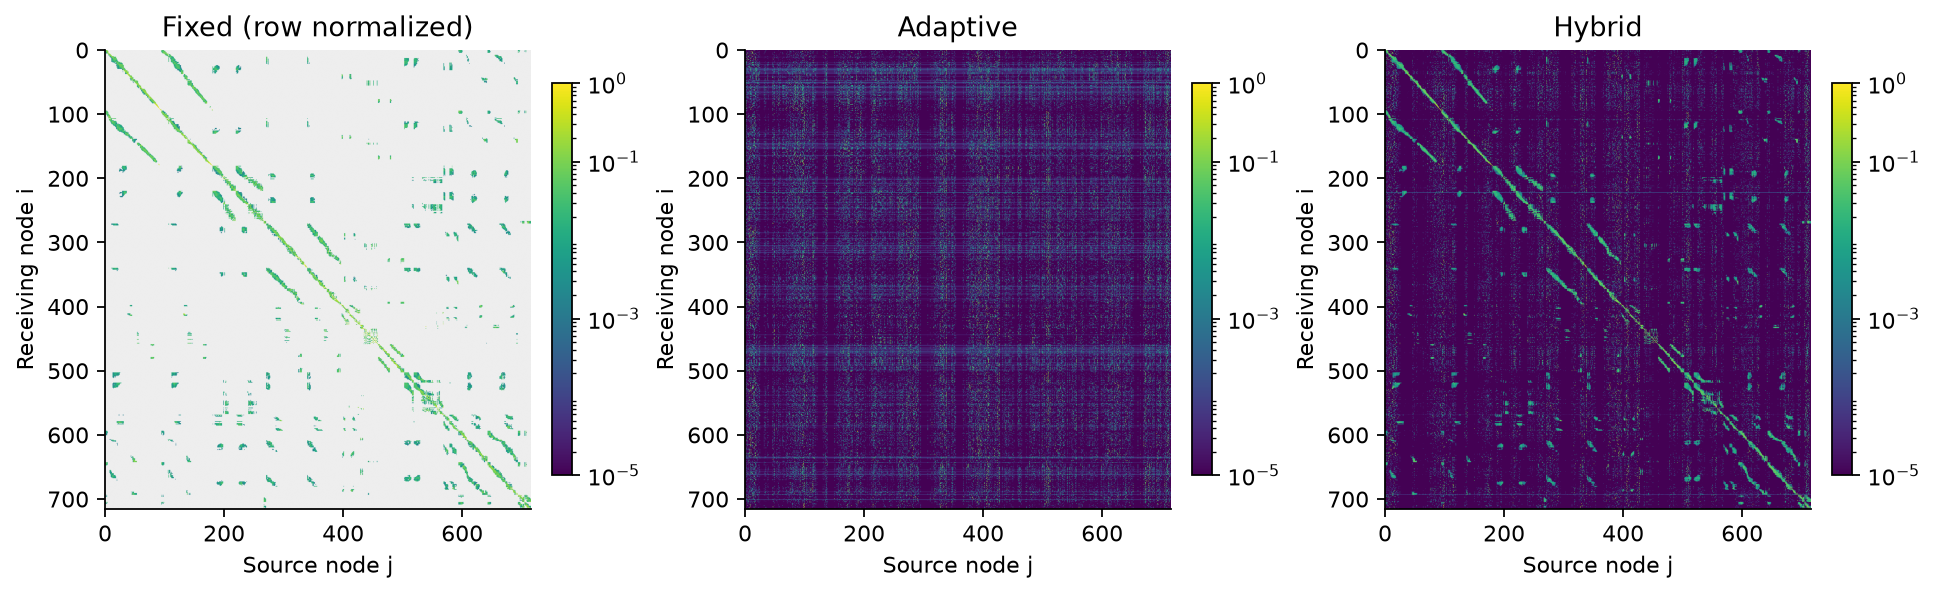

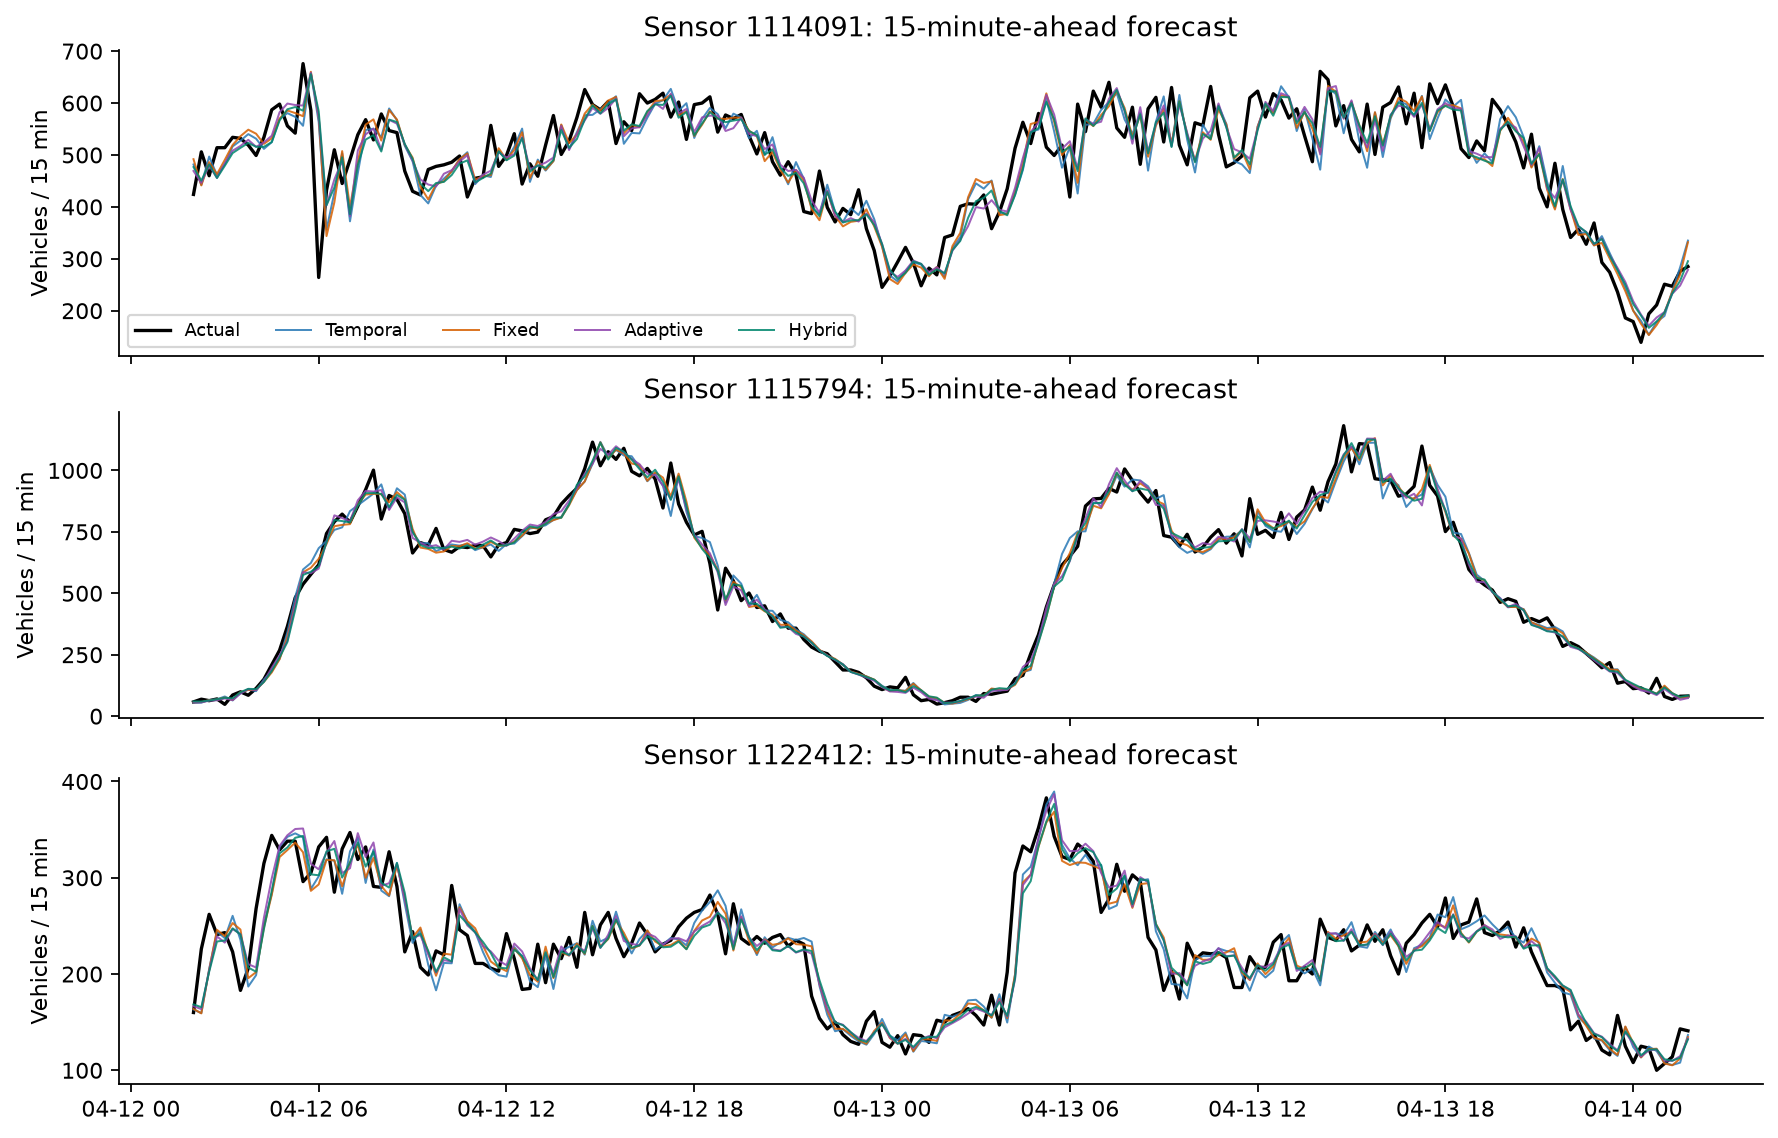

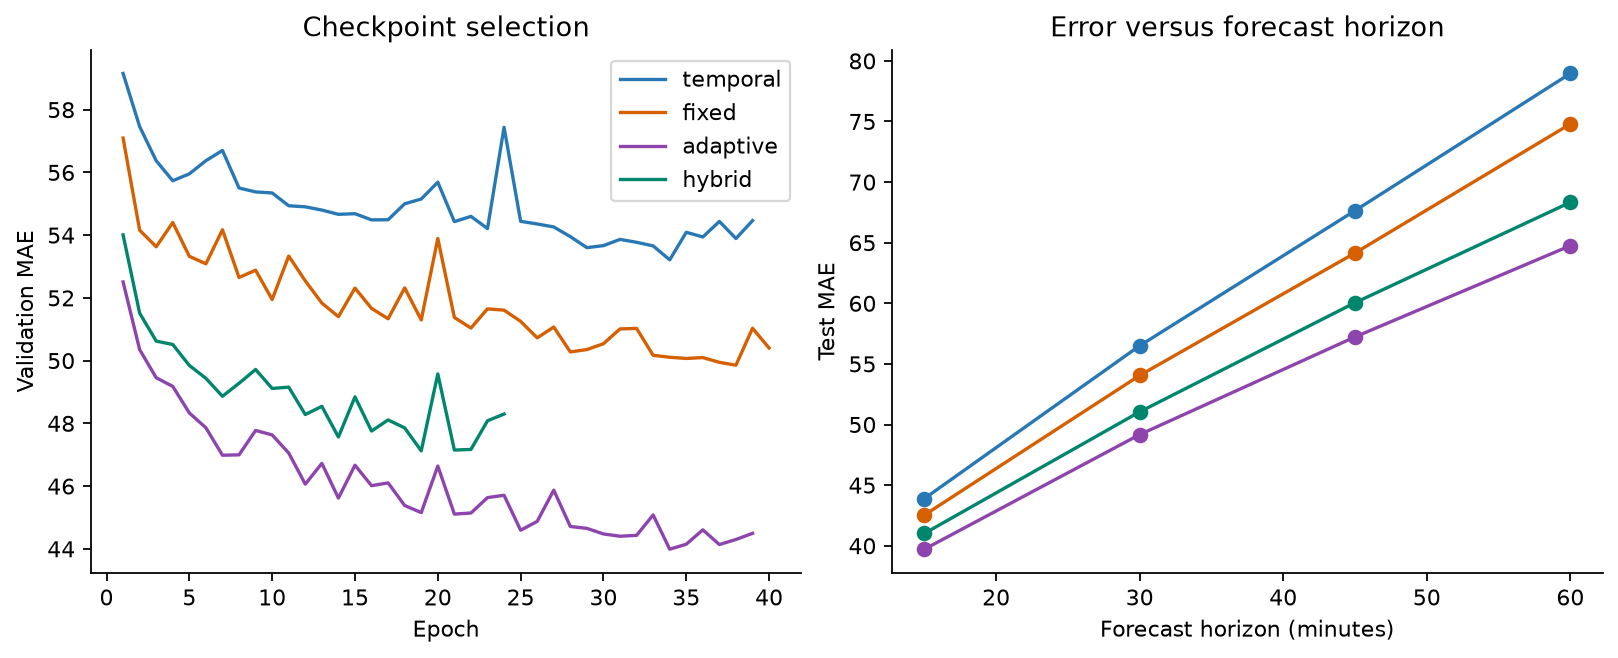

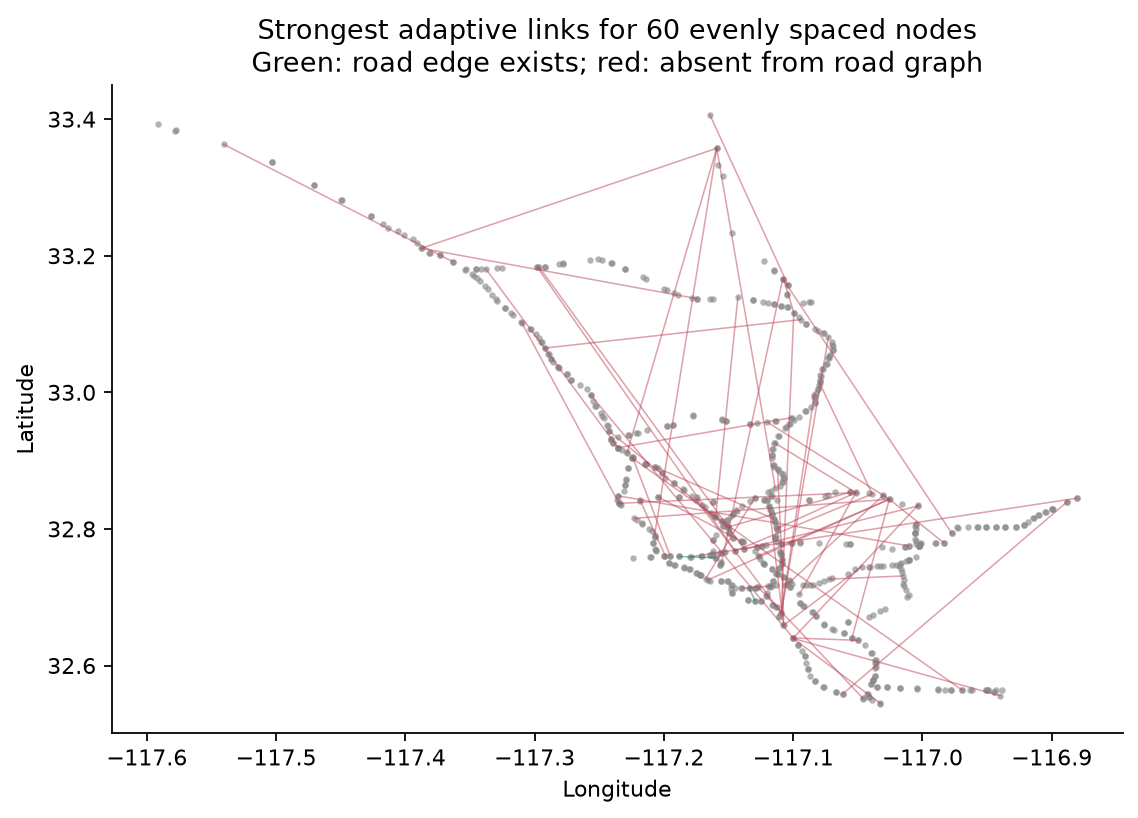

In [5]:
show('q5_adjacencies.png')
show('q6_predictions.png')
show('q6_learning.png')
show('q6_learned_map.png')